<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 📱 문자 메시지 스팸 가려내기 (심화) — 딥러닝

캐글 Code 득표 상위 「Simple LSTM for text classification」 흐름을 줄였어요(빠르게 돌도록 LSTM 대신 평균 풀링).

- (심화) 노트예요: 빈칸 없이 끝까지 돌아가요. 한 칸씩 실행하며 숫자와 그래프를 읽고, 보고서 「1-1·1-2·1-3」에 써요.

In [1]:
# 0. 준비 — 그대로 실행해요
!pip -q install koreanize-matplotlib   # 한글 그래프 글꼴
import koreanize_matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. 데이터 불러오기

In [2]:
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/spam.csv', encoding='latin-1')[['v1', 'v2']]
df.columns = ['정답', '문자']
y = (df['정답'] == 'spam').astype(int).values
print(df.shape, '스팸 비율', round(y.mean(), 3))

(5572, 2) 스팸 비율 0.134


## 2. 글 → 낱말 번호 (TextVectorization)

In [3]:
import keras
from keras import layers
keras.utils.set_random_seed(0)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['문자'].values, y, test_size=0.2, random_state=0, stratify=y)
vec = layers.TextVectorization(max_tokens=8000, output_sequence_length=40)
vec.adapt(X_train)

## 3. 신경망 — Embedding → 평균 → Dense

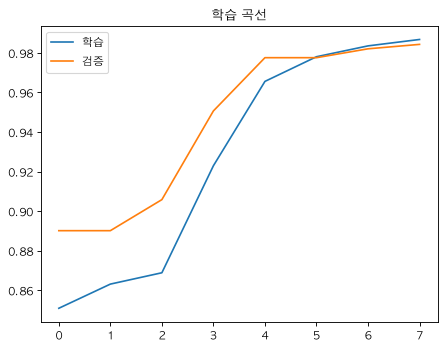

In [4]:
model = keras.Sequential([keras.Input(shape=(1,), dtype='string'), vec, layers.Embedding(8000, 32), layers.GlobalAveragePooling1D(), layers.Dense(16, activation='relu'), layers.Dense(1, activation='sigmoid')])
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
h = model.fit(X_train, y_train, epochs=8, batch_size=64, validation_split=0.1, verbose=0)
plt.plot(h.history['accuracy'], label='학습'); plt.plot(h.history['val_accuracy'], label='검증'); plt.legend(); plt.title('학습 곡선'); plt.show()

## 4. 성능평가

In [5]:
from sklearn.metrics import accuracy_score, f1_score
p = (model.predict(X_test, verbose=0)[:, 0] > 0.5).astype(int)
print('정확도', round(accuracy_score(y_test, p), 3), '· 스팸 F1', round(f1_score(y_test, p), 3))

정확도 0.943 · 스팸 F1 0.815
